Matplotlib is building the font cache; this may take a moment.


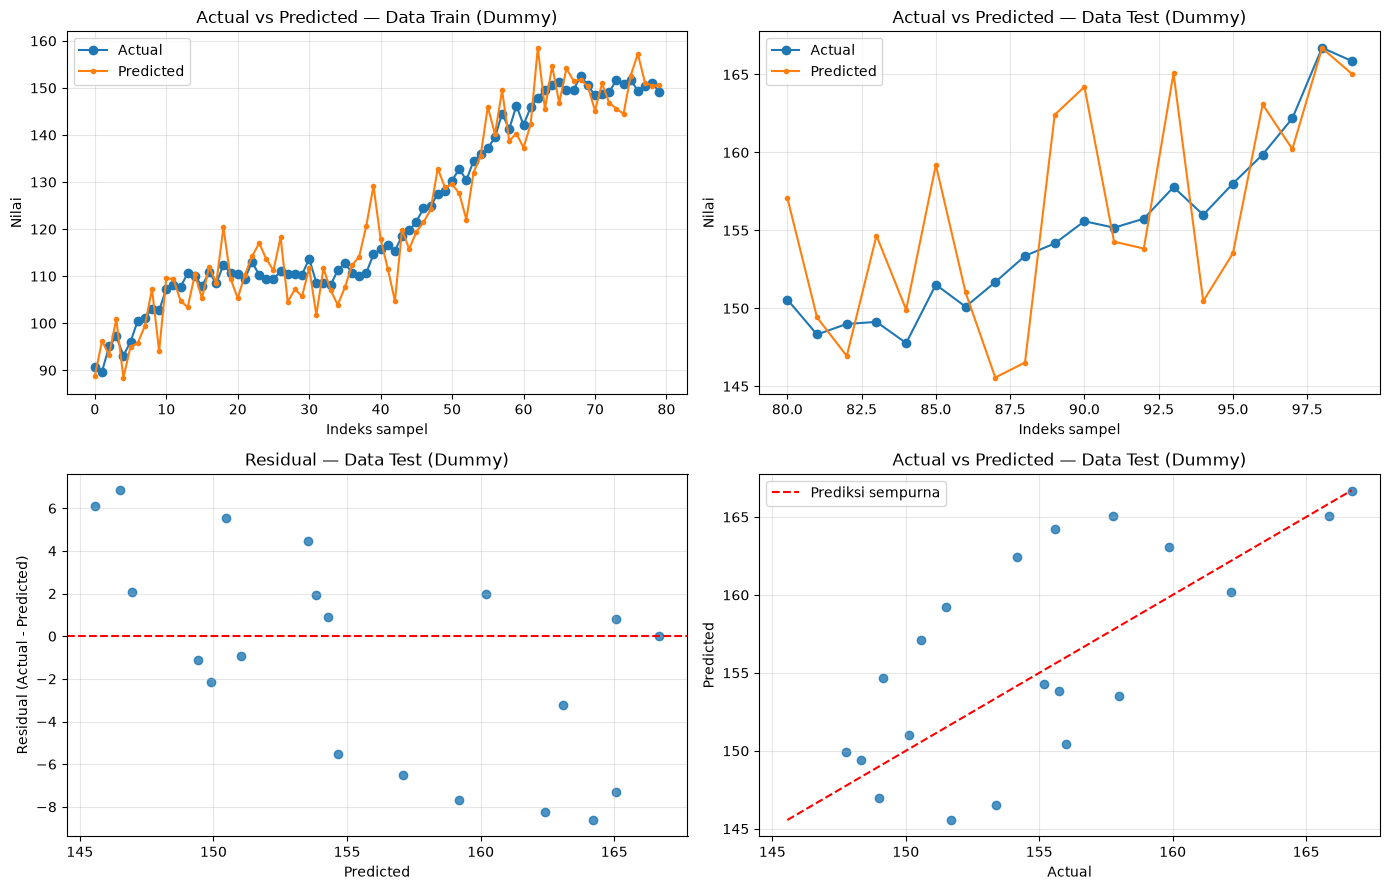

In [2]:
import numpy as np
import matplotlib.pyplot as plt

# Data dummy yang dibuat berurutan seperti data waktu.
rng = np.random.default_rng(42)
jumlah_sampel = 100
jumlah_train = 80

indeks = np.arange(jumlah_sampel)

# Nilai aktual dummy dengan tren dan sedikit variasi.
actual = (
    90
    + indeks * 0.8
    + 8 * np.sin(indeks / 8)
    + rng.normal(0, 2, jumlah_sampel)
)

# Prediksi dummy. Bukan hasil dari model ML sungguhan.
predicted = actual + rng.normal(0, 5, jumlah_sampel)

# Bagi secara berurutan: 80 data train, 20 data test.
y_train = actual[:jumlah_train]
prediksi_train = predicted[:jumlah_train]

y_test = actual[jumlah_train:]
prediksi_test = predicted[jumlah_train:]

# Residual = aktual - prediksi.
residual_test = y_test - prediksi_test

indeks_train = indeks[:jumlah_train]
indeks_test = indeks[jumlah_train:]

# Buat visualisasi.
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

# 1. Actual vs Predicted pada data train.
axes[0, 0].plot(indeks_train, y_train, marker="o", label="Actual")
axes[0, 0].plot(indeks_train, prediksi_train, marker=".", label="Predicted")
axes[0, 0].set_title("Actual vs Predicted — Data Train (Dummy)")
axes[0, 0].set_xlabel("Indeks sampel")
axes[0, 0].set_ylabel("Nilai")
axes[0, 0].legend()
axes[0, 0].grid(True, alpha=0.3)

# 2. Actual vs Predicted pada data test.
axes[0, 1].plot(indeks_test, y_test, marker="o", label="Actual")
axes[0, 1].plot(indeks_test, prediksi_test, marker=".", label="Predicted")
axes[0, 1].set_title("Actual vs Predicted — Data Test (Dummy)")
axes[0, 1].set_xlabel("Indeks sampel")
axes[0, 1].set_ylabel("Nilai")
axes[0, 1].legend()
axes[0, 1].grid(True, alpha=0.3)

# 3. Residual test terhadap nilai prediksi.
axes[1, 0].scatter(prediksi_test, residual_test, alpha=0.8)
axes[1, 0].axhline(0, color="red", linestyle="--")
axes[1, 0].set_title("Residual — Data Test (Dummy)")
axes[1, 0].set_xlabel("Predicted")
axes[1, 0].set_ylabel("Residual (Actual - Predicted)")
axes[1, 0].grid(True, alpha=0.3)

# 4. Actual vs Predicted test.
# Garis diagonal merah menunjukkan prediksi sempurna.
batas_min = min(y_test.min(), prediksi_test.min())
batas_maks = max(y_test.max(), prediksi_test.max())

axes[1, 1].scatter(y_test, prediksi_test, alpha=0.8)
axes[1, 1].plot(
    [batas_min, batas_maks],
    [batas_min, batas_maks],
    color="red",
    linestyle="--",
    label="Prediksi sempurna",
)
axes[1, 1].set_title("Actual vs Predicted — Data Test (Dummy)")
axes[1, 1].set_xlabel("Actual")
axes[1, 1].set_ylabel("Predicted")
axes[1, 1].legend()
axes[1, 1].grid(True, alpha=0.3)

fig.tight_layout()
plt.show()

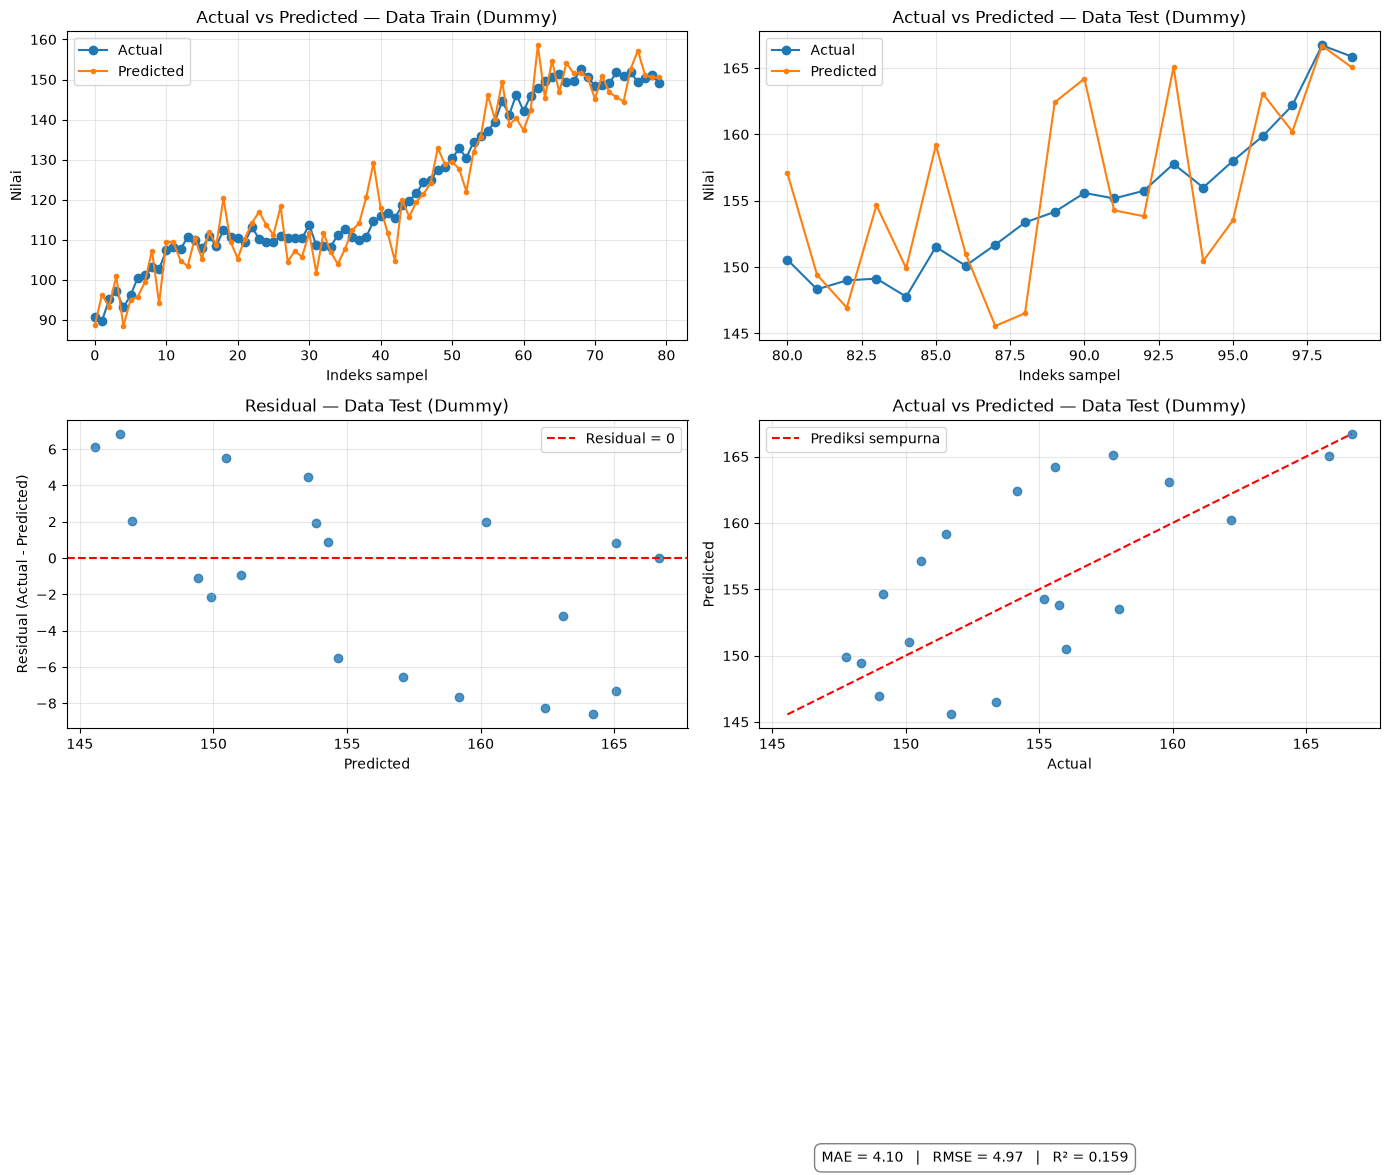

In [13]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


# Data dummy yang dibuat berurutan seperti data waktu.
rng = np.random.default_rng(42)
jumlah_sampel = 100
jumlah_train = 80

indeks = np.arange(jumlah_sampel)

# Nilai aktual dummy dengan tren dan sedikit variasi.
actual = (
    90
    + indeks * 0.8
    + 8 * np.sin(indeks / 8)
    + rng.normal(0, 2, jumlah_sampel)
)

# Prediksi dummy. Bukan hasil dari model ML sungguhan.
predicted = actual + rng.normal(0, 5, jumlah_sampel)

# Bagi secara berurutan: 80 data train, 20 data test.
y_train = actual[:jumlah_train]
prediksi_train = predicted[:jumlah_train]

y_test = actual[jumlah_train:]
prediksi_test = predicted[jumlah_train:]

# Residual = aktual - prediksi.
residual_test = y_test - prediksi_test

indeks_train = indeks[:jumlah_train]
indeks_test = indeks[jumlah_train:]

# Hitung metrik pada data test dummy.
mae_test = mean_absolute_error(y_test, prediksi_test)
rmse_test = np.sqrt(mean_squared_error(y_test, prediksi_test))
r2_test = r2_score(y_test, prediksi_test)

label_metrik = (
    f"MAE: {mae_test:.2f}\n"
    f"RMSE: {rmse_test:.2f}\n"
    f"R²: {r2_test:.3f}"
)

# Buat visualisasi.
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

# 1. Actual vs Predicted pada data train.
axes[0, 0].plot(indeks_train, y_train, marker="o", label="Actual")
axes[0, 0].plot(indeks_train, prediksi_train, marker=".", label="Predicted")
axes[0, 0].set_title("Actual vs Predicted — Data Train (Dummy)")
axes[0, 0].set_xlabel("Indeks sampel")
axes[0, 0].set_ylabel("Nilai")
axes[0, 0].legend()
axes[0, 0].grid(True, alpha=0.3)

# 2. Actual vs Predicted pada data test.
axes[0, 1].plot(indeks_test, y_test, marker="o", label="Actual")
axes[0, 1].plot(indeks_test, prediksi_test, marker=".", label="Predicted")
axes[0, 1].set_title("Actual vs Predicted — Data Test (Dummy)")
axes[0, 1].set_xlabel("Indeks sampel")
axes[0, 1].set_ylabel("Nilai")
axes[0, 1].legend()
axes[0, 1].grid(True, alpha=0.3)

# 3. Residual test terhadap nilai prediksi.
axes[1, 0].scatter(prediksi_test, residual_test, alpha=0.8)
axes[1, 0].axhline(
    0,
    color="red",
    linestyle="--",
    label="Residual = 0",
)
axes[1, 0].set_title("Residual — Data Test (Dummy)")
axes[1, 0].set_xlabel("Predicted")
axes[1, 0].set_ylabel("Residual (Actual - Predicted)")
axes[1, 0].legend()
axes[1, 0].grid(True, alpha=0.3)

# 4. Actual vs Predicted test.
# Garis diagonal merah menunjukkan prediksi sempurna.
batas_min = min(y_test.min(), prediksi_test.min())
batas_maks = max(y_test.max(), prediksi_test.max())

axes[1, 1].scatter(y_test, prediksi_test, alpha=0.8)
axes[1, 1].plot(
    [batas_min, batas_maks],
    [batas_min, batas_maks],
    color="red",
    linestyle="--",
    label="Prediksi sempurna",
)
axes[1, 1].set_title("Actual vs Predicted — Data Test (Dummy)")
axes[1, 1].set_xlabel("Actual")
axes[1, 1].set_ylabel("Predicted")
axes[1, 1].legend()
axes[1, 1].grid(True, alpha=0.3)

# Sisakan ruang di bawah plot untuk metrik.
fig.tight_layout(rect=[0, 0.12, 1, 1])

# Metrik ditampilkan di luar area plot, di bawah visualisasi.
fig.text(
    0.7,
    -0.30,
    f"MAE = {mae_test:.2f}   |   "
    f"RMSE = {rmse_test:.2f}   |   R² = {r2_test:.3f}",
    ha="center",
    va="bottom",
    bbox={
        "boxstyle": "round,pad=0.5",
        "facecolor": "white",
        "edgecolor": "gray",
    },
)

plt.show()

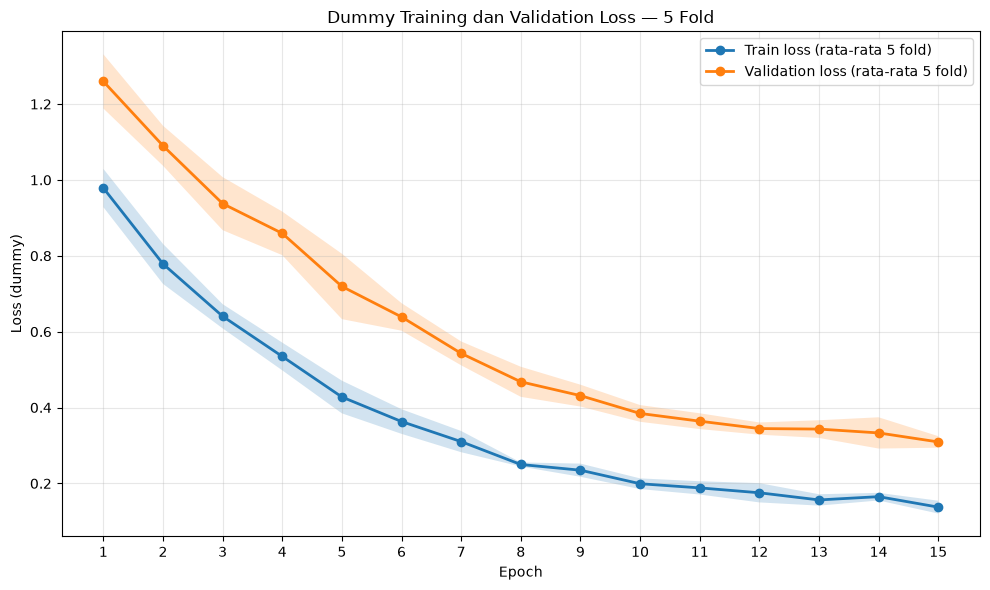

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Data dummy: 5 fold, masing-masing 15 epoch.
rng = np.random.default_rng(42)
jumlah_fold = 5
jumlah_epoch = 15
epoch = np.arange(1, jumlah_epoch + 1)

train_loss_semua_fold = []
validation_loss_semua_fold = []

for fold in range(jumlah_fold):
    # Simulasi loss yang secara umum turun selama training.
    train_awal = 1.0 + fold * 0.05
    validation_awal = 1.15 + fold * 0.06

    train_loss = (
        0.12
        + train_awal * np.exp(-0.25 * epoch)
        + rng.normal(0, 0.025, jumlah_epoch)
    )

    validation_loss = (
        0.22
        + validation_awal * np.exp(-0.19 * epoch)
        + rng.normal(0, 0.045, jumlah_epoch)
    )

    # Loss tidak mungkin negatif.
    train_loss = np.clip(train_loss, 0, None)
    validation_loss = np.clip(validation_loss, 0, None)

    train_loss_semua_fold.append(train_loss)
    validation_loss_semua_fold.append(validation_loss)

train_loss_semua_fold = np.array(train_loss_semua_fold)
validation_loss_semua_fold = np.array(validation_loss_semua_fold)

# Rata-rata dan standar deviasi loss pada setiap epoch dari 5 fold.
train_mean = train_loss_semua_fold.mean(axis=0)
train_std = train_loss_semua_fold.std(axis=0)

validation_mean = validation_loss_semua_fold.mean(axis=0)
validation_std = validation_loss_semua_fold.std(axis=0)

# Visualisasi rata-rata loss per epoch.
plt.figure(figsize=(10, 6))

plt.plot(
    epoch,
    train_mean,
    marker="o",
    linewidth=2,
    label="Train loss (rata-rata 5 fold)",
)
plt.fill_between(
    epoch,
    train_mean - train_std,
    train_mean + train_std,
    alpha=0.2,
)

plt.plot(
    epoch,
    validation_mean,
    marker="o",
    linewidth=2,
    label="Validation loss (rata-rata 5 fold)",
)
plt.fill_between(
    epoch,
    validation_mean - validation_std,
    validation_mean + validation_std,
    alpha=0.2,
)

plt.title("Dummy Training dan Validation Loss — 5 Fold")
plt.xlabel("Epoch")
plt.ylabel("Loss (dummy)")
plt.xticks(epoch)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()